# Case Study 12 — One Plan, Many Levels: Hierarchical, Probabilistic Demand Forecasting with Reconciliation (CLOVER-style) and the Service-Level Decision

**Priority:** ★★ Good to have · **Reference:** Case Study 12 — *Amazon Forecasting Science (CLOVER), with Flipkart CPP context* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Supply Chain Planning, Inventory and Replenishment, Network Design, Finance
**Data:** ⚠️ **SYNTHETIC** (D-12-01). Supply-chain demand data is confidential; this is a calibrated simulation with a hidden dependence structure.
**Evidence level of the reference:** Medium. The CLOVER paper is by an Amazon team but its experiments use six public datasets; Flipkart's planning platform is known only through a third-party summary. **Public method detail is thin. This notebook is an interview-standard solution on simulated data, not a reproduction of Amazon's or Flipkart's system.**
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs12_hierarchical_probabilistic_forecasting.ipynb`

## 0. Executive Summary for Business

«EXEC»

## 1. The Problem in Simple English

A retailer plans at several levels at once. The **national** team decides how much to buy. The **regional** team decides how to split stock between regions. Each **fulfilment centre (FC)** decides how much of each **category** to hold. If every level makes its own forecast, the numbers **do not add up**: the 16 FC forecasts sum to one number, the national forecast says another, and planners argue about which to trust.

There is a second problem. A single "expected demand" number is not enough to decide how much to stock. If a stock-out loses ₹135 of margin and a leftover unit costs ₹35 a week, the right amount to stock is not the average; it is a **high quantile** of the demand distribution. And the quantile for a whole region is **not** the sum of the quantiles of its FCs, because demand across FCs partly cancels out (pooling).

So we need forecasts that are:
1. **Coherent**: parts add up to the whole, at every level.
2. **Probabilistic**: a full range of outcomes, with honest uncertainty, not just a point.
3. **Dependence-aware**: it must know that FC demands move together, so that aggregate ranges are right.

Leaders and interviewers want to know:
1. Does forcing the forecasts to add up (**reconciliation**) make them more accurate, or just tidier?
2. Which level benefits, and which method is best: **bottom-up**, **top-down**, **OLS**, **WLS**, **MinT**, or a **factor-model (CLOVER-style)** sampler?
3. Are the **uncertainty ranges calibrated**, and what happens if we ignore dependence between series?
4. What does it change in **stock decisions and ₹**?

## 2. Reference from the Case File

### (a) What is documented

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Forecasts at different hierarchy levels must be **coherent** (add up) and **probabilistic**. The CLOVER paper (Olivares et al., arXiv 2307.09797, v4 revised 21 Dec 2024) cites supply-chain planning, resource allocation and retail demand as uses |
| Approach | An MQCNN-style encoder (dilated temporal convolutions) with MLP decoders; a **Gaussian multivariate factor model on the bottom-level series**; **coherence by construction** (aggregate the sampled bottom series); a residual cross-series MLP; the reparameterisation trick; training on **CRPS or Energy Score** |
| Evaluation | Scaled CRPS and Energy Score; 95% confidence intervals over 5 runs; last horizon window as test, the one before as validation. Six public datasets (Labour, Traffic, Tourism-S, Tourism-L, Wiki, Favorita). **No proprietary Amazon data** is described |
| Author claim | "average gains of 15%" in sCRPS over state-of-the-art coherent methods. The reference file notes the paper is internally inconsistent on Labour (about 8% degradation in one place, 4% in another) |
| Flipkart context | A Central Planning Platform (500 million users, 150 million products, 4 million daily shipments) with a forecasting layer (multiple granularities, hierarchical reconciliation) feeding an optimisation layer. Company claims via a summary: planning cycle cut from 10 days to 1; **data and method detail not disclosed** (the original blog returned 403) |

**Sources:** arXiv 2307.09797v4 (CLOVER); Flipkart Tech blog post on the Central Planning Platform (read only through a daily.dev summary).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | Weekly units for a national retailer: 4 regions, 16 FCs, 6 categories = **96 bottom series, 117 nodes**, 208 weeks. Bottom means range from about 5 to 900 units a week. Yearly shape, festive weeks (Republic Day sale, Diwali/Big Billion Days, year-end), category trends, shared shocks at national, region, category and FC level, negative-binomial counts |
| Base forecast | A per-series regression on log demand (trend, yearly Fourier terms, festive flags) with a block bootstrap of residuals for sample paths. Deliberately simple, so that **differences come from reconciliation, not from a better base model** |
| Methods compared | (1) Base (incoherent); (2) bottom-up; (3) bottom-up with **independent** sampling; (4) top-down; (5) OLS; (6) WLS (structural); (7) **MinT with shrinkage**; (8) **CLOVER-style**: Gaussian factor model on bottom log residuals, coherent by construction. **We do not train a neural network or optimise CRPS directly; this is the statistical idea of CLOVER, not the model** |
| Statistics added | Rolling-origin evaluation (13 origins); scaled CRPS by level; interval coverage; Energy Score; paired cluster bootstrap over origins and node-level Wilcoxon with Holm; dependence diagnostics; newsvendor cost at the service-level quantile; the pooling effect; a power calculation for the number of evaluation windows |

### (c) How the industry uses this

Hierarchical forecasting with reconciliation (bottom-up, top-down, MinT) is standard in retail and supply-chain planning; probabilistic forecasts feed safety-stock and service-level targets. Deep probabilistic models (DeepAR, MQCNN, CLOVER-like) are used when there are hundreds of thousands of series. Indian marketplaces and quick-commerce firms plan at national, region, city, FC or dark-store, and SKU levels, so the problem is real; the specific methods used in their production systems are mostly not public.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How should we forecast demand at every level so that plans agree, and how much stock should each node hold for a target service level? |
| Analytical | Which coherent probabilistic method gives the best scaled CRPS across levels out of time, are its ranges calibrated, and does the better distribution lower stock cost? |

**Hypotheses**
- **H1:** H0: reconciled forecasts have the same scaled CRPS as the incoherent base forecasts (paired, origins as clusters; node-level Wilcoxon).
- **H2:** H0: the best reconciliation method equals the others in overall scaled CRPS (Holm across comparisons).
- **H3 (dependence):** H0: ignoring cross-series dependence (independent bottom-up sampling) gives the same 80% interval coverage at the upper levels as dependence-preserving sampling.
- **H4 (decision):** H0: ordering at the cost-based service-level quantile of the best method costs the same as ordering at the point forecast.
- **H5 (pooling):** H0: the sum of FC-level 95% safety buffers equals the region-level buffer.

**Primary metric:** scaled CRPS (sum of CRPS / sum of actuals), per level and averaged over the four levels. **Diagnostics:** 80% interval coverage, Energy Score, WAPE of the mean. **Decision metric:** newsvendor cost in ₹.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import FactorAnalysis
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Amazon / Flipkart supply-chain demand | **Not public.** The CLOVER paper uses public sets only. |
| Public hierarchical sets (Tourism, Favorita, M5, Traffic) | **None is Indian ecommerce demand with a known dependence structure**; some are Kaggle-hosted and large. |
| **Decision** | Synthetic hierarchy with a known shock structure, so that we can check whether dependence-aware methods recover it (D-12-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs12.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 12 (hierarchical, probabilistic demand forecasting; CLOVER-style)
======================================================================================================
THIS DATA IS SYNTHETIC. Supply-chain demand data of Amazon or Flipkart is confidential. CLOVER (arXiv 2307.09797)
uses six public datasets, not Amazon production data. Flipkart's Central Planning Platform is known only through a
third-party summary. Nothing here reproduces either system.

Simulation: weekly unit demand for a national retailer, 208 weeks (Jan 2022 to Dec 2025).
Hierarchy: Total (1) > Region (4) > Fulfilment centre (16) > FC x Category (96 bottom series). 117 nodes in all.
  * Level: FC size and category mix differ a lot (weekly means from about 5 to 900 units).
  * Seasonality: yearly Fourier shape per category, plus festive weeks (Republic Day sale, Big Billion Days / Diwali,
    year-end) with category-specific lifts. Category trends differ.
  * Dependence (the point of the case): the log-demand carries shared AR(1) shocks at national, region, category
    and FC level, so bottom series are positively correlated, and aggregates are NOT as noisy as independent
    series would imply (or as quiet).
  * Counts: negative binomial around exp(log-demand).
Built-in messiness: 3 FC outages (all categories reported as 0 for 2 to 3 weeks), 12 keying errors (x10), 150 duplicate rows.
Hidden truth (prefix _): true mean, shock components.

Outputs (written by the notebook): data/cs12/demand_weekly.csv.gz, data/cs12/hierarchy.csv
"""
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2022-01-03"); T = 208
REGIONS = ["North", "South", "West", "East"]
FCS = {"North": ["Delhi", "Gurugram", "Lucknow", "Ludhiana"], "South": ["Bengaluru", "Chennai", "Hyderabad", "Kochi"],
       "West": ["Mumbai", "Pune", "Ahmedabad", "Jaipur"], "East": ["Kolkata", "Patna", "Bhubaneswar", "Guwahati"]}
CATS = ["Mobiles", "Fashion", "Home & Kitchen", "Grocery & FMCG", "Beauty", "Electronics accessories"]
# (base weekly units per FC, yearly trend (log/yr), seasonal amplitude, Republic Day lift, BBD/Diwali lift, year-end lift)
CATP = {"Mobiles": (60, 0.06, 0.08, 0.15, 0.60, 0.10), "Fashion": (120, 0.10, 0.20, 0.25, 0.45, 0.20),
        "Home & Kitchen": (45, 0.08, 0.10, 0.20, 0.50, 0.05), "Grocery & FMCG": (260, 0.14, 0.05, 0.02, 0.15, 0.10),
        "Beauty": (30, 0.18, 0.12, 0.10, 0.35, 0.25), "Electronics accessories": (14, 0.04, 0.06, 0.10, 0.40, 0.08)}


def _ar1(rng, n, rho, sd):
    e = rng.normal(0, sd * np.sqrt(1 - rho ** 2), n); x = np.zeros(n); x[0] = rng.normal(0, sd)
    for i in range(1, n):
        x[i] = rho * x[i - 1] + e[i]
    return x


def festive(dates):
    wk = dates.isocalendar().week.values.astype(int)
    return {"republic": np.isin(wk, [3, 4]).astype(float), "bbd": np.isin(wk, [40, 41, 42, 43]).astype(float) * np.array([0.6, 1.0, 1.0, 0.8])[np.clip(wk - 40, 0, 3)],
            "yearend": np.isin(wk, [51, 52]).astype(float)}


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    dates = pd.date_range(START, periods=T, freq="W-MON"); t = np.arange(T); fe = festive(dates); doy = dates.dayofyear.values / 365.25
    nat = _ar1(rng, T, 0.80, 0.05); reg = {r: _ar1(rng, T, 0.75, 0.06) for r in REGIONS}; cat_sh = {c: _ar1(rng, T, 0.75, 0.07) for c in CATS}
    rows, hier = [], []
    for r in REGIONS:
        for f in FCS[r]:
            size = np.exp(rng.normal(0, 0.55)) * {"North": 1.1, "South": 1.0, "West": 1.25, "East": 0.7}[r]; fcs = _ar1(rng, T, 0.70, 0.05)
            for c in CATS:
                base, tr, amp, rl, bl, yl = CATP[c]; mixj = np.exp(rng.normal(0, 0.35)); phase = rng.uniform(0, 1)
                seas = amp * np.sin(2 * np.pi * (doy + phase * 0.15)) + 0.5 * amp * np.cos(4 * np.pi * doy)
                own = _ar1(rng, T, 0.5, 0.04)
                lm = np.log(base * size * mixj) + tr * t / 52.0 + seas + rl * fe["republic"] + bl * fe["bbd"] + yl * fe["yearend"] + nat + reg[r] + cat_sh[c] + fcs + own
                mu = np.exp(lm); theta = 25.0
                y = rng.negative_binomial(theta, theta / (theta + mu))
                rows.append(pd.DataFrame({"week": dates, "region": r, "fc": f, "category": c, "units": y, "_mu": mu}))
                hier.append((r, f, c))
    df = pd.concat(rows, ignore_index=True)
    # messiness: FC outages (reported zero for all categories), keying errors, duplicate rows
    out_specs = [("Patna", 60, 3), ("Kochi", 118, 2), ("Pune", 146, 3)]
    for fc, w0, n in out_specs:
        m = (df.fc == fc) & df.week.isin(dates[w0:w0 + n]); df.loc[m, "units"] = 0
    idx = rng.choice(np.where(df.units > 5)[0], 12, replace=False); df.loc[idx, "units"] = df.loc[idx, "units"] * 10
    dup = df.sample(150, random_state=seed); df = pd.concat([df, dup], ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df, pd.DataFrame(hier, columns=["region", "fc", "category"])


if __name__ == "__main__":
    d, h = generate()
    print(d.shape, d.units.describe())

Overwriting data/generate_cs12.py


In [3]:
os.makedirs("data/cs12", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs12 as gen; importlib.reload(gen)
t0 = time.time(); raw, hier = gen.generate(seed=SEED); raw.to_csv("data/cs12/demand_weekly.csv.gz", index=False); hier.to_csv("data/cs12/hierarchy.csv", index=False)
print(f"{len(raw):,} rows | {raw.groupby(['region', 'fc', 'category']).ngroups} bottom series | {raw.week.nunique()} weeks | generated in {time.time() - t0:.1f}s")
raw.head(4)

20,118 rows | 96 bottom series | 208 weeks | generated in 4.0s


,week,region,fc,category,units,_mu
0,2022-09-05,North,Delhi,Home & Kitchen,53,52.7408
1,2024-01-08,East,Patna,Beauty,11,13.0297
2,2024-02-05,North,Ludhiana,Home & Kitchen,57,64.3717
3,2024-11-25,East,Patna,Fashion,125,107.5703


| Parameter | Value | Basis |
|---|---|---|
| Hierarchy | Total > 4 regions > 16 FCs > 96 FC×category series (117 nodes) | Our assumption (Flipkart: planning at multiple granularities, detail ND) |
| Length | 208 weeks (Jan 2022 to Dec 2025) | Our assumption |
| Level | FC size lognormal (σ 0.55); category base 14 to 260 units per FC-week | Our assumption |
| Seasonality | Yearly Fourier shape per category; Republic Day, Big Billion Days/Diwali (weeks 40 to 43), year-end lifts | Typical Indian ecommerce calendar; sizes assumed |
| Shared shocks | AR(1) log shocks: national (sd 0.05), region (0.06), category (0.07), FC (0.05), own (0.04) | Our assumption (hidden truth) |
| Counts | Negative binomial, dispersion θ = 25 | Our assumption |
| DQ issues | 3 FC outages (zeros for 2 to 3 weeks), 12 keying errors (×10), 150 duplicate rows | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("demand_weekly: week, region, fc, category, units", "Week start (Monday), location in the hierarchy, units shipped"), ("_mu", "HIDDEN: true expected units (used only to describe the simulation, never to forecast)"),
    ("hierarchy: region, fc, category", "Parent-child structure of the 96 bottom series"),
    ("derived nodes", "Total, 4 regions and 16 FCs are sums of the bottom series (summing matrix S, 117 x 96)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs12/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"demand_weekly: week, region, fc, category, units","Week start (Monday), location in the hierarchy..."
1,_mu,HIDDEN: true expected units (used only to desc...
2,"hierarchy: region, fc, category",Parent-child structure of the 96 bottom series
3,derived nodes,"Total, 4 regions and 16 FCs are sums of the bo..."


## 5. Data Quality Checks

In [5]:
nd = int(raw.duplicated(["week", "fc", "category"]).sum()); df = raw.drop_duplicates(["week", "fc", "category"]).copy()
fcw = df.groupby(["fc", "week"]).units.sum().unstack(0); zero_fcw = (fcw == 0)
outages = [(fc, str(zero_fcw.index[zero_fcw[fc]][0].date()), int(zero_fcw[fc].sum())) for fc in fcw.columns if zero_fcw[fc].any()]
df = df.sort_values(["region", "fc", "category", "week"]).reset_index(drop=True)
keys = df[["region", "fc", "category"]].drop_duplicates().reset_index(drop=True)
Yb = df.pivot_table(index="week", columns=["region", "fc", "category"], values="units", sort=False).reindex(columns=pd.MultiIndex.from_frame(keys))
out_mask = np.zeros(Yb.shape, bool)
for j, (r, f, c) in enumerate(Yb.columns): out_mask[:, j] = zero_fcw[f].reindex(Yb.index).values
Yv = Yb.values.astype(float); Yv[out_mask] = np.nan
roll = pd.DataFrame(Yv).rolling(9, center=True, min_periods=3).median().values; ratio = Yv / np.maximum(roll, 1)
key_err = (ratio > 5) & (Yv > 20); n_key = int(key_err.sum()); Yv[key_err] = roll[key_err]
n_out = int(out_mask.sum()); Yv = pd.DataFrame(Yv).interpolate(limit_direction="both").values
print(f"duplicate rows removed: {nd} | FC outages found (fc, first week, weeks): {outages} | outage cells imputed: {n_out} | keying errors repaired: {n_key}")
Yclean = Yv; DATES = Yb.index; T = len(DATES); NB = Yclean.shape[1]
print(f"clean panel: {T} weeks x {NB} bottom series | weekly units per bottom series: median {np.median(Yclean.mean(0)):.0f}, min {Yclean.mean(0).min():.1f}, max {Yclean.mean(0).max():.0f} | zero weeks left: {(Yclean == 0).sum()}")

duplicate rows removed: 150 | FC outages found (fc, first week, weeks): [('Kochi', '2024-04-08', 2), ('Patna', '2023-02-27', 3), ('Pune', '2024-10-21', 3)] | outage cells imputed: 48 | keying errors repaired: 12
clean panel: 208 weeks x 96 bottom series | weekly units per bottom series: median 62, min 5.6, max 836 | zero weeks left: 6


**Observation:** «O5»

## 6. Hierarchy and Exploratory Data Analysis

nodes: 117 (total 1, regions 4, FCs 16, bottom 96) | S matrix (117, 96) | coherence check max |Yall[:, 0] - sum of bottom| = 0.0e+00
share of total units by category: {'Beauty': 0.068, 'Electronics accessories': 0.021, 'Fashion': 0.246, 'Grocery & FMCG': 0.479, 'Home & Kitchen': 0.079, 'Mobiles': 0.108}


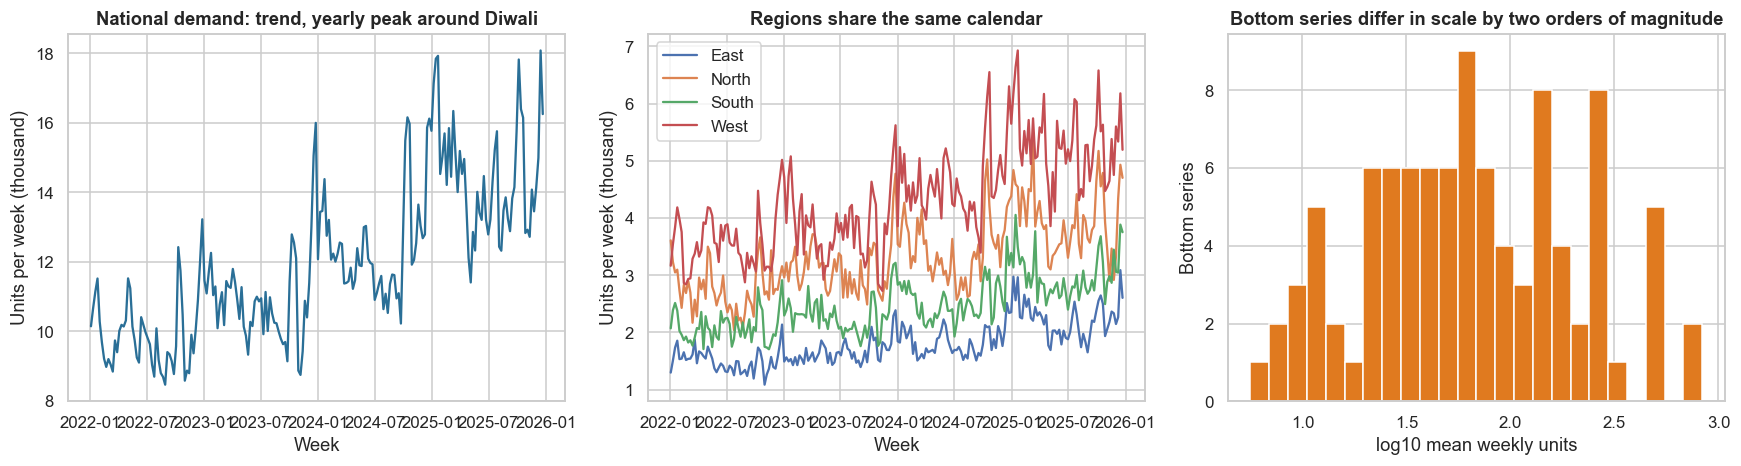

national units by year: {2022: 0.52, 2023: 0.57, 2024: 0.66, 2025: 0.74} (million)


In [6]:
regs = [k[0] for k in Yb.columns]; fcs = [k[1] for k in Yb.columns]; cats = [k[2] for k in Yb.columns]
REGS = list(dict.fromkeys(regs)); FCL = list(dict.fromkeys(fcs)); CATL = list(dict.fromkeys(cats))
Smat = np.zeros((1 + len(REGS) + len(FCL) + NB, NB)); Smat[0] = 1
for i, r in enumerate(REGS): Smat[1 + i] = [x == r for x in regs]
for i, f in enumerate(FCL): Smat[1 + len(REGS) + i] = [x == f for x in fcs]
Smat[1 + len(REGS) + len(FCL):] = np.eye(NB); NN = Smat.shape[0]
level = np.r_[0, np.ones(len(REGS)), 2 * np.ones(len(FCL)), 3 * np.ones(NB)].astype(int); LV = ["Total", "Region", "FC", "FC × category"]
names = ["Total"] + REGS + FCL + [f"{f} | {c}" for f, c in zip(fcs, cats)]
Yall = Yclean @ Smat.T
print(f"nodes: {NN} (total 1, regions {len(REGS)}, FCs {len(FCL)}, bottom {NB}) | S matrix {Smat.shape} | coherence check max |Yall[:, 0] - sum of bottom| = {np.abs(Yall[:, 0] - Yclean.sum(1)).max():.1e}")
print("share of total units by category:", (pd.Series(Yclean.sum(0)).groupby(cats).sum() / Yclean.sum()).round(3).to_dict())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(DATES, Yall[:, 0] / 1e3, color="#2a6f97"); axes[0].set_xlabel("Week"); axes[0].set_ylabel("Units per week (thousand)"); axes[0].set_title("National demand: trend, yearly peak around Diwali")
for r in REGS: axes[1].plot(DATES, Yall[:, 1 + REGS.index(r)] / 1e3, label=r)
axes[1].legend(); axes[1].set_xlabel("Week"); axes[1].set_ylabel("Units per week (thousand)"); axes[1].set_title("Regions share the same calendar")
axes[2].hist(np.log10(Yclean.mean(0)), bins=24, color="#e07a1f"); axes[2].set_xlabel("log10 mean weekly units"); axes[2].set_ylabel("Bottom series"); axes[2].set_title("Bottom series differ in scale by two orders of magnitude")
plt.tight_layout(); plt.show()
yr = pd.Series(Yall[:, 0], index=DATES).groupby(DATES.year).sum(); print("national units by year:", (yr / 1e6).round(2).to_dict(), "(million)")

**Takeaway:** «O61»

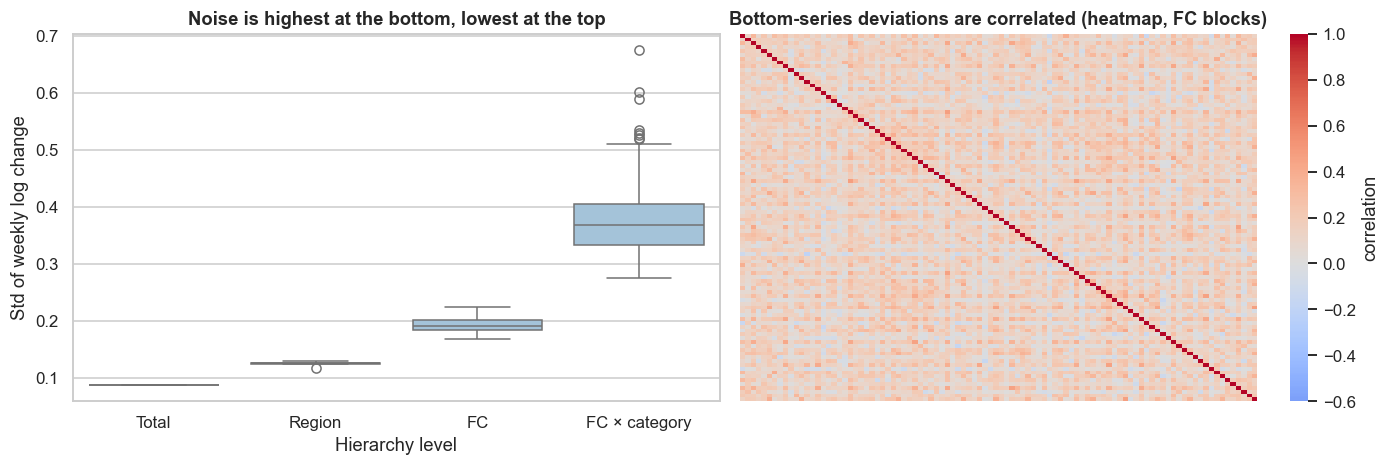

median weekly log-change std: Total: 0.088, Region: 0.125, FC: 0.190, FC × category: 0.368 | mean pairwise correlation of detrended bottom series: 0.130 (share of pairs above 0.2: 23.4%)


In [7]:
cv = pd.DataFrame({"level": [LV[l] for l in level]}); cv["cv"] = [np.std(np.diff(np.log1p(Yall[:, i]))) for i in range(NN)]; cv["mean_units"] = Yall.mean(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.boxplot(data=cv, x="level", y="cv", order=LV, ax=axes[0], color="#9bc4e2"); axes[0].set_xlabel("Hierarchy level"); axes[0].set_ylabel("Std of weekly log change"); axes[0].set_title("Noise is highest at the bottom, lowest at the top")
res_b = np.log1p(Yclean) - pd.DataFrame(np.log1p(Yclean)).rolling(13, min_periods=1).mean().values; cb = np.corrcoef(res_b[13:].T)
order_ = np.lexsort((cats, fcs)); sns.heatmap(cb[np.ix_(order_, order_)], cmap="coolwarm", center=0, vmin=-0.6, vmax=1, ax=axes[1], xticklabels=False, yticklabels=False, cbar_kws={"label": "correlation"}); axes[1].set_title("Bottom-series deviations are correlated (heatmap, FC blocks)")
plt.tight_layout(); plt.show()
off = cb[np.triu_indices(NB, 1)]; print(f"median weekly log-change std: " + ", ".join(f"{l}: {cv[cv.level == l].cv.median():.3f}" for l in LV) + f" | mean pairwise correlation of detrended bottom series: {off.mean():.3f} (share of pairs above 0.2: {(off > 0.2).mean():.1%})")

**Takeaway:** «O62»

## 7. Statistical Analysis (core section)

### 7.1 Setup: rolling-origin evaluation, base probabilistic forecasts and eight coherent or incoherent methods

**Protocol:** 13 forecast origins, 4 weeks apart, the last origin 8 weeks before the end of data; at each origin we train on everything before it and forecast the next **8 weeks** (windows overlap; see the caveat in 7.3). The same calendar flags (festive weeks) are known in advance and used as regressors.

**Base model (every node, separately):** OLS on log(1 + units) with trend, 3 yearly Fourier pairs and three festive flags. It is deliberately basic: all methods share it, so differences are due to how forecasts are made coherent and how uncertainty is sampled.

**Sample paths:** 500 paths per origin. Residuals of the 117 nodes are resampled **in time blocks of 8 weeks, jointly across all nodes**, so cross-series dependence and serial correlation survive. Paths are converted to units and floored at 0.

| # | Method | In one line |
|---|---|---|
| 1 | Base | The 117 independent forecasts (incoherent: parts do not add up) |
| 2 | Bottom-up (BU) | Keep only the 96 bottom paths; aggregate them |
| 3 | BU, independent sampling | Same, but each bottom series draws its residual block **independently**: ignores dependence |
| 4 | Top-down | Take the national path and split by historical average shares |
| 5 | OLS | Project all base paths onto the coherent space, equal weights |
| 6 | WLS (structural) | As OLS, weights = number of bottom series under each node |
| 7 | **MinT-shrink** | Projection weighted by the inverse of the shrunk covariance of in-sample errors (Wickramasuriya et al.) |
| 8 | **CLOVER-style** | Bottom log-residuals follow a Gaussian factor model (6 factors, AR(1) scores); sample bottom paths and aggregate. Coherent by construction. No neural net, no CRPS training |

Negative reconciled values are clipped at 0 at the bottom and re-aggregated, so every coherent method stays coherent and non-negative.

#### Code

In [8]:
doy = DATES.dayofyear.values / 365.25; wk = DATES.isocalendar().week.values.astype(int)
FE = gen.festive(DATES)
XD = np.column_stack([np.ones(T), np.arange(T) / 52.0] + [f(2 * np.pi * k * doy) for k in (1, 2, 3) for f in (np.sin, np.cos)] + [FE["republic"], FE["bbd"], FE["yearend"]])
H, NS, QS = 8, 500, np.round(np.arange(0.05, 0.951, 0.05), 2)
METHODS = ["1 Base (incoherent)", "2 Bottom-up", "3 Bottom-up, independent", "4 Top-down", "5 OLS", "6 WLS (structural)", "7 MinT-shrink", "8 CLOVER-style (factor)"]
B0 = NN - NB
def mint_cov(res):
    n = len(res); sd = res.std(0, ddof=1) + 1e-9; Z = res / sd; R = np.corrcoef(Z.T); Zc = Z - Z.mean(0)
    v = ((Zc[:, :, None] * Zc[:, None, :]) ** 2).mean(0) * n / (n - 1) ** 2 * 1.0; off_ = ~np.eye(R.shape[0], dtype=bool); lam = np.clip(v[off_].sum() / (R[off_] ** 2).sum(), 0, 1)
    Rs = (1 - lam) * R + lam * np.eye(R.shape[0]); return Rs * np.outer(sd, sd), lam
def proj(Wi):
    A = Smat.T @ Wi; return np.linalg.solve(A @ Smat, A)
def forecast_origin(o, seed):
    rg = np.random.default_rng(seed); Ztr = np.log1p(Yall[:o]); Xtr, Xte = XD[:o], XD[o:o + H]
    beta = np.linalg.lstsq(Xtr, Ztr, rcond=None)[0]; fit = Xtr @ beta; res = Ztr - fit; infl = np.sqrt(o / (o - XD.shape[1])); mlog = Xte @ beta
    st = rg.integers(0, o - H + 1, NS); idx = st[:, None] + np.arange(H); LS = mlog[None] + res[idx] * infl; base = np.clip(np.expm1(LS), 0, None)
    st_i = rg.integers(0, o - H + 1, (NS, NB)); idx_i = st_i[:, None, :] + np.arange(H)[None, :, None]; resb = res[:, B0:]; LSb = mlog[None, :, B0:] + resb[idx_i, np.arange(NB)[None, None, :]] * infl
    bu_ind = np.clip(np.expm1(LSb), 0, None)
    lev_res = Yall[:o] - np.expm1(fit); out = {"base": base}
    def coh(bottom): return np.clip(bottom, 0, None) @ Smat.T
    out["bu"] = coh(base[:, :, B0:]); out["bu_ind"] = coh(bu_ind)
    tot = Yall[:o, 0]; pshare = (Yclean[:o] / tot[:, None]).mean(0); Ptd = np.zeros((NB, NN)); Ptd[:, 0] = pshare; out["td"] = coh(base @ Ptd.T)
    Pols = proj(np.eye(NN)); out["ols"] = coh(base @ Pols.T)
    Wd = np.diag(1.0 / Smat.sum(1)); out["wls"] = coh(base @ proj(Wd).T)
    Wm, lam = mint_cov(lev_res); Pm = proj(np.linalg.inv(Wm + 1e-6 * np.trace(Wm) / NN * np.eye(NN))); out["mint"] = coh(base @ Pm.T)
    fa = FactorAnalysis(n_components=6, random_state=SEED, max_iter=300).fit(resb); sc = fa.transform(resb); rho = np.array([np.corrcoef(sc[1:, k], sc[:-1, k])[0, 1] for k in range(6)])
    z = np.zeros((NS, H, 6)); z[:, 0] = rg.normal(0, 1, (NS, 6))
    for h in range(1, H): z[:, h] = rho * z[:, h - 1] + np.sqrt(1 - rho ** 2) * rg.normal(0, 1, (NS, 6))
    eps = rg.normal(0, 1, (NS, H, NB)) * np.sqrt(fa.noise_variance_); rs = z @ fa.components_ + eps; out["clover"] = coh(np.clip(np.expm1(mlog[None, :, B0:] + rs * infl), 0, None))
    out["_lam"] = lam; out["_rho"] = rho; out["_res"] = res; out["_levres"] = lev_res
    return out
KEYS = ["base", "bu", "bu_ind", "td", "ols", "wls", "mint", "clover"]
ORIGINS = [T - H - 4 * k for k in range(12, -1, -1)]
def pinball_crps(samp, y):
    q = np.quantile(samp, QS, axis=0); d = y[None] - q; return 2 * np.mean(np.maximum(QS[:, None, None] * d, (QS[:, None, None] - 1) * d), axis=0), q
def energy_score(samp, y, scale):
    X = samp / scale; yy = y / scale; a = np.linalg.norm(X - yy, axis=2).mean(0); half = NS // 2; b = np.linalg.norm(X[:half] - X[half:2 * half], axis=2).mean(0); return a - 0.5 * b
O = len(ORIGINS); C = np.zeros((len(KEYS), O, H, NN)); COV = np.zeros_like(C); WID = np.zeros_like(C); AE = np.zeros_like(C); ES = np.zeros((len(KEYS), O, H, 2)); QB = np.zeros((len(KEYS), O, H, len(QS), NB)); MEANF = np.zeros_like(C); Q95 = np.zeros_like(C)
LAM, RHO, LEVRES = [], [], {}
t0 = time.time()
for oi, o in enumerate(ORIGINS):
    out = forecast_origin(o, SEED + oi); y = Yall[o:o + H]; sc_ = Yall[:o].mean(0)
    for ki, k in enumerate(KEYS):
        smp = out[k]; c, q = pinball_crps(smp, y); C[ki, oi] = c; lo, hi = q[1], q[-2]; COV[ki, oi] = (y >= lo) & (y <= hi); WID[ki, oi] = hi - lo
        MEANF[ki, oi] = smp.mean(0); AE[ki, oi] = np.abs(y - MEANF[ki, oi]); Q95[ki, oi] = q[-1]; QB[ki, oi] = q[:, :, B0:].transpose(1, 0, 2)
        ES[ki, oi, :, 0] = energy_score(smp[:, :, B0:], y[:, B0:], sc_[B0:]); ES[ki, oi, :, 1] = energy_score(smp, y, sc_)
    LAM.append(out["_lam"]); RHO.append(out["_rho"]); LEVRES[o] = out["_levres"]
print(f"{O} origins x {H} weeks x {NN} nodes x {len(KEYS)} methods scored in {time.time() - t0:.0f}s | MinT shrinkage intensity (mean over origins) {np.mean(LAM):.2f} | factor-score AR(1) rho (mean) {np.mean(RHO):.2f}")
YT = np.stack([Yall[o:o + H] for o in ORIGINS])
def slevel(Carr, mask_o=slice(None)):
    return np.array([Carr[mask_o][..., level == l].sum() / YT[mask_o][..., level == l].sum() for l in range(4)])
SC = pd.DataFrame({m: slevel(C[i]) for i, m in enumerate(METHODS)}, index=LV).T; SC["overall (mean of levels)"] = SC.mean(1); SC["vs base (%)"] = (SC.iloc[:, -1] / SC.iloc[0, -1] - 1) * 100
cov_ = pd.DataFrame({m: [COV[i][..., level == l].mean() for l in range(4)] for i, m in enumerate(METHODS)}, index=LV).T
wape = pd.DataFrame({m: [AE[i][..., level == l].sum() / YT[..., level == l].sum() for l in range(4)] for i, m in enumerate(METHODS)}, index=LV).T
esdf = pd.DataFrame({m: [ES[i][..., 0].mean(), ES[i][..., 1].mean()] for i, m in enumerate(METHODS)}, index=["Energy Score: bottom (scaled)", "Energy Score: all nodes (scaled)"]).T
print("Scaled CRPS (lower is better); 'vs base' = overall change in %"); SC.round(4)

13 origins x 8 weeks x 117 nodes x 8 methods scored in 65s | MinT shrinkage intensity (mean over origins) 0.39 | factor-score AR(1) rho (mean) 0.31
Scaled CRPS (lower is better); 'vs base' = overall change in %


,Total,Region,FC,FC × category,overall (mean of levels),vs base (%)
1 Base (incoherent),0.0564,0.0692,0.0961,0.1530,0.0937,0.0000
2 Bottom-up,0.0555,0.0686,0.0961,0.1530,0.0933,-0.4172
"3 Bottom-up, independent",0.0586,0.0699,0.0962,0.1527,0.0943,0.7175
4 Top-down,0.0564,0.0720,0.1026,0.1844,0.1038,10.8539
5 OLS,0.0563,0.0693,0.0964,0.1535,0.0938,0.1859
6 WLS (structural),0.0560,0.0690,0.0962,0.1533,0.0936,-0.0540
7 MinT-shrink,0.0559,0.0689,0.0961,0.1531,0.0935,-0.1853
8 CLOVER-style (factor),0.0555,0.0686,0.0960,0.1527,0.0932,-0.5053


**(c)/(f) Observation:** «O71»

#### Coverage, point accuracy and the Energy Score

In [9]:
allm = pd.concat([cov_.add_prefix("80% coverage: "), wape.add_prefix("WAPE: "), esdf], axis=1)
print("Nominal 80% interval coverage should be 0.80; WAPE = sum|y - mean forecast| / sum y; Energy Score lower is better")
allm.round(3)

Nominal 80% interval coverage should be 0.80; WAPE = sum|y - mean forecast| / sum y; Energy Score lower is better


,80% coverage: Total,80% coverage: Region,80% coverage: FC,80% coverage: FC × category,WAPE: Total,WAPE: Region,WAPE: FC,WAPE: FC × category,Energy Score: bottom (scaled),Energy Score: all nodes (scaled)
1 Base (incoherent),0.6540,0.7430,0.7610,0.7750,0.0730,0.0910,0.1290,0.2050,2.4930,2.5730
2 Bottom-up,0.6540,0.7620,0.7730,0.7750,0.0720,0.0900,0.1290,0.2050,2.4930,2.5730
"3 Bottom-up, independent",0.4330,0.6200,0.7250,0.7740,0.0720,0.0900,0.1290,0.2040,2.4840,2.5630
4 Top-down,0.6540,0.5220,0.3790,0.2060,0.0730,0.0910,0.1240,0.2090,3.2890,3.3570
5 OLS,0.6540,0.7450,0.7640,0.7820,0.0730,0.0910,0.1290,0.2050,2.5240,2.6030
6 WLS (structural),0.6630,0.7520,0.7680,0.7780,0.0730,0.0900,0.1290,0.2050,2.5100,2.5900
7 MinT-shrink,0.6630,0.7570,0.7680,0.7760,0.0730,0.0900,0.1290,0.2040,2.4940,2.5740
8 CLOVER-style (factor),0.6630,0.7310,0.7600,0.7780,0.0720,0.0900,0.1290,0.2050,2.4820,2.5610


**(c)/(f) Observation:** «O72»

### 7.2 Coherence: how incoherent is the base forecast?

**(a) Why?** If base forecasts disagree across levels, planners must adjust by hand. We measure, for the base method, the gap between each parent's mean forecast and the sum of its children's, as a share of the parent's forecast, then confirm that the coherent methods have zero gap.

#### Code

In [10]:
mb = MEANF[0]; gaps = []
for l, lab in ((0, "Total vs sum of 96 bottom"), (1, "Region vs sum of its bottom series"), (2, "FC vs sum of its bottom series")):
    idxs = np.where(level == l)[0]; gp = []
    for i in idxs:
        kids = np.where(Smat[i] > 0)[0]; gp.append(np.abs(mb[..., i] - mb[..., B0 + kids].sum(-1)) / np.maximum(mb[..., i], 1e-9))
    gaps.append((lab, np.mean(gp), np.max(np.mean(gp, axis=(1, 2))) if False else np.percentile(np.array(gp).ravel(), 95)))
cg = pd.DataFrame(gaps, columns=["comparison", "mean |gap| / parent forecast", "95th percentile"]).set_index("comparison")
viol = {m: float(np.abs(MEANF[i][..., 0] - MEANF[i][..., B0:].sum(-1)).max()) for i, m in enumerate(METHODS)}
print("max |total mean forecast - sum of bottom mean forecasts| (units):", {m.split(" ", 1)[0]: round(v, 3) for m, v in viol.items()})
cg.round(4)

max |total mean forecast - sum of bottom mean forecasts| (units): {'1': 171.863, '2': 0.0, '3': 0.0, '4': 0.0, '5': 0.0, '6': 0.0, '7': 0.0, '8': 0.0}


,mean |gap| / parent forecast,95th percentile
comparison,,
Total vs sum of 96 bottom,0.0066,0.0117
Region vs sum of its bottom series,0.0063,0.0114
FC vs sum of its bottom series,0.0065,0.0146


**Observation:** «O73»

### 7.3 Is reconciliation really better? Paired tests

**(a) Why?** Methods are scored on the same nodes, origins and weeks, so differences are paired. Weeks inside a forecast window and neighbouring origins overlap, and nodes are correlated, so a naive test over node-weeks would overstate certainty. We use two conservative views:
- **Cluster bootstrap over the 13 origins** (resample origins with replacement) for the difference in overall scaled CRPS (mean of levels), with a 95% interval.
- **Wilcoxon signed-rank over the 117 nodes** on each node's scaled CRPS (node CRPS divided by the node's mean demand), Holm-corrected across the comparisons with the best method.

The best method is the one with the lowest overall scaled CRPS.

#### Code

In [11]:
def overall_by_origin(Ck):
    return np.array([np.mean([Ck[oi][..., level == l].sum() / YT[oi][..., level == l].sum() for l in range(4)]) for oi in range(O)])
OBO = np.array([overall_by_origin(C[i]) for i in range(len(KEYS))]); bi = int(np.argmin(OBO.mean(1))); NSC = np.array([C[i].sum((0, 1)) / YT.sum((0, 1)) for i in range(len(KEYS))])
rows = []
for i, m in enumerate(METHODS):
    if i == bi: continue
    d = OBO[i] - OBO[bi]; bs = np.array([d[RNG.integers(0, O, O)].mean() for _ in range(2000)]); w = stats.wilcoxon(NSC[i], NSC[bi])
    rows.append((m, d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), int((d > 0).sum()), np.mean(NSC[i] > NSC[bi]), w.pvalue))
pt = pd.DataFrame(rows, columns=[f"vs {METHODS[bi]}", "Δ overall sCRPS (other − best)", "CI low", "CI high", f"origins where best wins (of {O})", "share of nodes where best wins", "Wilcoxon p (nodes)"]).set_index(f"vs {METHODS[bi]}")
pt["p_holm"] = multipletests(pt["Wilcoxon p (nodes)"], method="holm")[1]
print(f"Best overall: {METHODS[bi]} | overall sCRPS by origin: sd {OBO[bi].std():.4f}")
pt.round(4)

Best overall: 8 CLOVER-style (factor) | overall sCRPS by origin: sd 0.0109


,Δ overall sCRPS (other − best),CI low,CI high,origins where best wins (of 13),share of nodes where best wins,Wilcoxon p (nodes),p_holm
vs 8 CLOVER-style (factor),,,,,,,
1 Base (incoherent),0.0004,-0.0006,0.0015,9,0.5385,0.4520,1.0000
2 Bottom-up,0.0001,-0.0006,0.0008,5,0.5385,0.6963,1.0000
"3 Bottom-up, independent",0.0011,0.0006,0.0017,11,0.4615,0.4153,1.0000
4 Top-down,0.0107,0.0087,0.0123,13,0.9744,0.0000,0.0000
5 OLS,0.0006,-0.0006,0.0018,9,0.7607,0.0000,0.0000
6 WLS (structural),0.0004,-0.0005,0.0014,9,0.7009,0.0000,0.0000
7 MinT-shrink,0.0003,-0.0006,0.0012,9,0.5726,0.2026,0.8103


**Observation:** «O74»

### 7.4 Level by level, and calibration with and without dependence

The overall number hides where each method helps. The chart shows scaled CRPS relative to the base by level, and the coverage of the nominal 80% interval. The test of H3 compares dependence-preserving bottom-up (2) with independent bottom-up (3) at each level: a **binomial test** that coverage equals 0.80, treating each node-origin as a trial (optimistic, because trials are correlated; read p-values as a guide).

#### Code

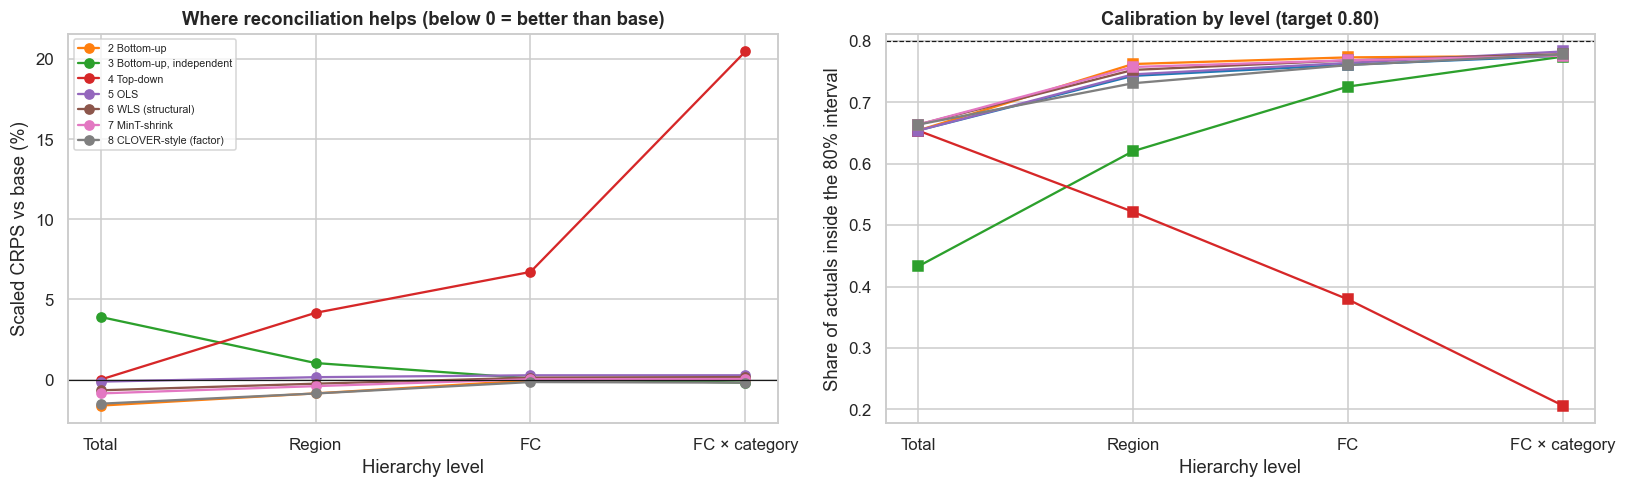

Best-vs-base change in sCRPS by level (%): {'Total': -1.5, 'Region': -0.9, 'FC': -0.2, 'FC × category': -0.2}


coverage                          binomial p (H0: 0.80)                         
method        2 Bottom-up 3 Bottom-up, independent           2 Bottom-up 3 Bottom-up, independent
level                                                                                            
Total              0.6540                   0.4330                0.0010                   0.0000
Region             0.7620                   0.6200                0.0570                   0.0000
FC                 0.7730                   0.7250                0.0060                   0.0000
FC × category      0.7750                   0.7740                0.0000                   0.0000

In [12]:
rel = (SC.iloc[:, :4].div(SC.iloc[0, :4]) - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6)); pal = sns.color_palette("tab10", len(METHODS))
for i, m in enumerate(METHODS[1:], 1): axes[0].plot(LV, rel.loc[m].values, marker="o", color=pal[i], label=m)
axes[0].axhline(0, color="k", lw=0.8); axes[0].legend(fontsize=7); axes[0].set_xlabel("Hierarchy level"); axes[0].set_ylabel("Scaled CRPS vs base (%)"); axes[0].set_title("Where reconciliation helps (below 0 = better than base)")
for i, m in enumerate(METHODS): axes[1].plot(LV, cov_.loc[m].values, marker="s", color=pal[i], label=m)
axes[1].axhline(0.8, color="k", ls="--", lw=0.8); axes[1].set_xlabel("Hierarchy level"); axes[1].set_ylabel("Share of actuals inside the 80% interval"); axes[1].set_title("Calibration by level (target 0.80)")
plt.tight_layout(); plt.show()
bt = []
for l in range(4):
    for i in (1, 2):
        k_ = int(COV[i][..., level == l].sum()); n_ = COV[i][..., level == l].size; bt.append((LV[l], METHODS[i], k_ / n_, stats.binomtest(k_, n_, 0.8).pvalue))
bt = pd.DataFrame(bt, columns=["level", "method", "coverage", "binomial p (H0: 0.80)"]).pivot(index="level", columns="method", values=["coverage", "binomial p (H0: 0.80)"]).loc[LV]
print("Best-vs-base change in sCRPS by level (%):", rel.loc[METHODS[bi]].round(1).to_dict()); bt.round(3)

**Takeaway:** «O75»

### 7.5 Dependence: what the data say about how series move together

**(a) Why?** Coherent probabilistic forecasts are only right if the **joint** distribution is right. At the last origin we compute the correlation of bottom-series log residuals by relationship (same FC, same region, same category, unrelated) and compare the realised variance of the total with what independence would give: Var(total error) ÷ Σ Var(bottom error), both in units. A ratio above 1 means errors add up rather than cancel.

#### Code

In [13]:
lr = LEVRES[ORIGINS[-1]][:, B0:]; o_ = ORIGINS[-1]; res_last = np.log1p(Yall[:o_]) - XD[:o_] @ np.linalg.lstsq(XD[:o_], np.log1p(Yall[:o_]), rcond=None)[0]; rb = res_last[:, B0:]; cr = np.corrcoef(rb.T)
rg_, fc_, ct_ = np.array(regs), np.array(fcs), np.array(cats); iu = np.triu_indices(NB, 1); a, b = iu
rel_ = np.select([fc_[a] == fc_[b], (rg_[a] == rg_[b]) & (ct_[a] == ct_[b]), rg_[a] == rg_[b], ct_[a] == ct_[b]], ["same FC, other category", "same region, same category", "same region, other category", "other region, same category"], "other region, other category")
dep = pd.DataFrame({"relationship": rel_, "corr": cr[iu]}).groupby("relationship")["corr"].agg(["mean", "std", "count"]).sort_values("mean", ascending=False)
ratios = {}
for l in range(4):
    ratios[LV[l]] = float(np.mean([lr_var for lr_var in [np.var(LEVRES[ORIGINS[-1]][:, i]) / max(sum(np.var(LEVRES[ORIGINS[-1]][:, B0 + j]) for j in np.where(Smat[i] > 0)[0]), 1e-9) for i in np.where(level == l)[0]]]))
print("Var(error of node) / sum of Var(errors of its bottom series), in units (1 = independent):", {k: round(v, 2) for k, v in ratios.items()})
dep.round(3)

Var(error of node) / sum of Var(errors of its bottom series), in units (1 = independent): {'Total': 3.02, 'Region': 1.89, 'FC': 1.2, 'FC × category': 1.0}


,mean,std,count
relationship,,,
"same region, same category",0.1150,0.0830,144
"other region, same category",0.0730,0.0830,576
"same FC, other category",0.0720,0.0740,240
"same region, other category",0.0530,0.0740,720
"other region, other category",0.0120,0.0740,2880


**Observation:** «O76»

### 7.6 Does the better distribution lower stock cost? Newsvendor at the service-level quantile

**(a) Why?** The business uses the distribution through a stock decision. At each FC×category we choose a stock quantity Q for the next week. A unit short loses ₹135 of margin (**cu**, assumption); a leftover unit costs ₹35 for the week in holding and markdown risk (**co**, assumption). The cost-minimising Q is the **cu / (cu + co) quantile** of the demand distribution (here 0.79). We score each method's ordering quantile, plus an "order the mean forecast" baseline (a point forecast), against realised demand over all 13 × 8 test node-weeks at the bottom level.

**Test for H4:** paired difference of cost per bottom node-week, cluster bootstrap over origins.

#### Code

In [14]:
CU, CO = 135.0, 35.0; QSTAR = CU / (CU + CO)
def order_q(i, q):
    pos = (q - QS[0]) / (QS[1] - QS[0]); lo = int(np.clip(np.floor(pos), 0, len(QS) - 2)); w = min(max(pos - lo, 0.0), 1.0); return (1 - w) * QB[i, :, :, lo, :] + w * QB[i, :, :, lo + 1, :]
def cost(Q, y, cu=CU, co=CO): return cu * np.maximum(y - Q, 0) + co * np.maximum(Q - y, 0)
YB = YT[..., B0:]; costs = {}
costs["Point forecast (mean of base)"] = cost(MEANF[0][..., B0:], YB)
for i, m in enumerate(METHODS): costs[m] = cost(order_q(i, QSTAR), YB)
cdf = pd.DataFrame({"₹ per bottom node-week": {k: v.mean() for k, v in costs.items()}}); cdf["service level achieved"] = [np.mean(MEANF[0][..., B0:] >= YB)] + [np.mean(order_q(i, QSTAR) >= YB) for i in range(len(METHODS))]
cdf["₹ lakh per year (96 series)"] = cdf.iloc[:, 0] * NB * 52 / 1e5; cdf["vs point forecast (%)"] = (cdf.iloc[:, 0] / cdf.iloc[0, 0] - 1) * 100
print(f"critical ratio q* = {QSTAR:.3f} | cu = ₹{CU:.0f}, co = ₹{CO:.0f}"); cdf.round(3)

critical ratio q* = 0.794 | cu = ₹135, co = ₹35


,₹ per bottom node-week,service level achieved,₹ lakh per year (96 series),vs point forecast (%)
Point forecast (mean of base),"2,743.8260",0.4920,136.9720,0.0000
1 Base (incoherent),"2,046.4590",0.7450,102.1590,-25.4160
2 Bottom-up,"2,046.4590",0.7450,102.1590,-25.4160
"3 Bottom-up, independent","2,043.0080",0.7450,101.9870,-25.5420
4 Top-down,"2,526.1800",0.6140,126.1070,-7.9320
5 OLS,"2,050.0190",0.7330,102.3370,-25.2860
6 WLS (structural),"2,049.4000",0.7360,102.3060,-25.3090
7 MinT-shrink,"2,045.9050",0.7430,102.1320,-25.4360
8 CLOVER-style (factor),"2,045.0020",0.7410,102.0870,-25.4690


**Observation:** «O77»

#### Pooling: sum of FC-level buffers vs the region-level buffer

**H5:** a coherent joint distribution lets us compare holding a 95%-quantile buffer at every FC×category (the sum of 95% quantiles minus the sum of means) with a single buffer for the whole region (95% quantile of the regional sum minus its mean). The gap is the pooling benefit, available only if stock can be shared or rebalanced inside the region. For the **independent** bottom-up method the gap is wrongly large.

#### Code

In [15]:
rows = []
for i in (1, 2, 6, 7):
    for l, lab in ((1, "Region"), (2, "FC")):
        sep = []; pooled = []
        for n_ in np.where(level == l)[0]:
            kids = B0 + np.where(Smat[n_] > 0)[0]; sep.append((Q95[i][..., kids] - MEANF[i][..., kids]).sum(-1)); pooled.append(Q95[i][..., n_] - MEANF[i][..., n_])
        s_, p_ = np.mean(sep), np.mean(pooled); rows.append((METHODS[i], lab, s_, p_, 1 - p_ / s_))
pl = pd.DataFrame(rows, columns=["method", "pooled at", "sum of bottom buffers (units/week/node)", "single buffer (units/week/node)", "buffer saved by pooling"]).set_index(["method", "pooled at"])
print("buffer = 95% quantile minus mean of weekly demand; averaged over nodes, origins, weeks"); pl.round(3)

buffer = 95% quantile minus mean of weekly demand; averaged over nodes, origins, weeks


sum of bottom buffers (units/week/node)  single buffer (units/week/node)  buffer saved by pooling
method                   pooled at                                                                                                   
2 Bottom-up              Region                                  1,552.9180                         627.1380                   0.5960
                         FC                                        388.2300                         229.6940                   0.4080
3 Bottom-up, independent Region                                  1,550.5540                         453.7640                   0.7070
                         FC                                        387.6380                         211.5290                   0.4540
7 MinT-shrink            Region                                  1,542.9830                         620.0740                   0.5980
                         FC                                        385.7460                         226.8820                   0.4120
8 CLOVER-style (factor)  Region                                  1,593.8430                         599.2350                   0.6240
                         FC                                        398.4610                         231.6790                   0.4190

**Observation:** «O78»

### 7.7 Fan chart: what the planner sees at two levels

#### Code

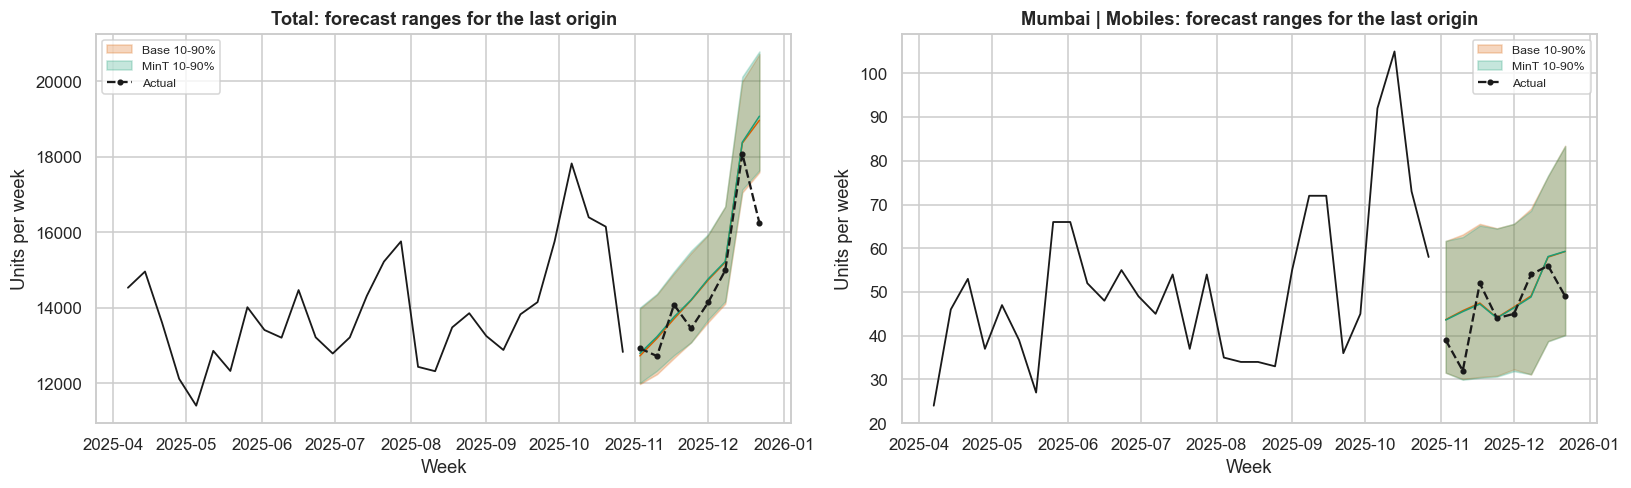

last origin week: 2025-11-03 | MinT total width (10-90%) mean: 2449.0 vs base: 2457.0


In [16]:
oo = ORIGINS[-1]; outl = forecast_origin(oo, SEED + O - 1); node_ids = [0, int(np.where(np.array(names) == "Mumbai | Mobiles")[0][0])]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6)); wk_tr = DATES[oo - 30:oo]; wk_te = DATES[oo:oo + H]
for ax, n_ in zip(axes, node_ids):
    for k_, col, lab in (("base", "#d95f02", "Base 10-90%"), ("mint", "#1b9e77", "MinT 10-90%")):
        q = np.quantile(outl[k_][:, :, n_], [0.1, 0.5, 0.9], axis=0); ax.fill_between(wk_te, q[0], q[2], alpha=0.25, color=col, label=lab); ax.plot(wk_te, q[1], color=col, lw=1)
    ax.plot(wk_tr, Yall[oo - 30:oo, n_], color="k", lw=1.2); ax.plot(wk_te, Yall[oo:oo + H, n_], color="k", ls="--", marker="o", ms=3, label="Actual"); ax.legend(fontsize=8)
    ax.set_xlabel("Week"); ax.set_ylabel("Units per week"); ax.set_title(f"{names[n_]}: forecast ranges for the last origin")
plt.tight_layout(); plt.show()
print("last origin week:", DATES[oo].date(), "| MinT total width (10-90%) mean:", round(float(np.mean(np.diff(np.quantile(outl['mint'][:, :, 0], [0.1, 0.9], axis=0), axis=0))), 0), "vs base:", round(float(np.mean(np.diff(np.quantile(outl['base'][:, :, 0], [0.1, 0.9], axis=0), axis=0))), 0))

**Takeaway:** «O79»

### 7.8 How many evaluation windows do we need? Power for comparing two methods

We use the spread of the per-origin difference in overall scaled CRPS between the best method and the base to ask how many independent evaluation windows are needed to detect a given relative improvement (paired t-approximation, 80% power, α = 0.05, two-sided). Overlapping windows are not independent, so we use non-overlapping 8-week windows as the unit.

#### Code

In [17]:
d_best = OBO[0] - OBO[bi]; sd_d = d_best.std(ddof=1); base_lvl = OBO[0].mean(); rows = []
for rel_imp in (0.02, 0.05, 0.10):
    delta = rel_imp * base_lvl; n_need = int(np.ceil(((1.96 + 0.84) * sd_d / delta) ** 2)); rows.append((f"{rel_imp:.0%}", delta, n_need, n_need * 8))
pw_ = pd.DataFrame(rows, columns=["relative improvement to detect", "absolute Δ sCRPS", "independent 8-week windows needed", "weeks of history needed"]).set_index("relative improvement to detect")
print(f"per-origin difference (base − {METHODS[bi]}): mean {d_best.mean():.4f}, sd {sd_d:.4f}; base overall sCRPS {base_lvl:.4f}; we have {O} origins ≈ {O * 4 / 8:.1f} non-overlapping windows"); pw_.round(4)

per-origin difference (base − 8 CLOVER-style (factor)): mean 0.0004, sd 0.0020; base overall sCRPS 0.0935; we have 13 origins ≈ 6.5 non-overlapping windows


,absolute Δ sCRPS,independent 8-week windows needed,weeks of history needed
relative improvement to detect,,,
2%,0.0019,10,80
5%,0.0047,2,16
10%,0.0094,1,8


**Observation:** «O710»

## 8. ML Section — a global model against per-series models

CLOVER-type systems train **one global model for all series**. We test the simplest version of that idea on the bottom-level **point** forecast: a single gradient-boosting model (`HistGradientBoostingRegressor`, defaults) trained across all 96 series on log demand relative to each series' training mean, with calendar and series features, against the per-series regressions used above. Same 13 origins, 8-week horizons. No tuning.

#### Code

In [18]:
t0 = time.time(); cat_code = pd.Series(cats).astype("category").cat.codes.values; reg_code = pd.Series(regs).astype("category").cat.codes.values
def gbm_origin(o):
    Ztr = np.log1p(Yclean[:o]); mu = Ztr.mean(0); rows = np.arange(o)
    Xf = lambda r: np.column_stack([np.repeat(XD[r][:, 1:], NB, axis=0), np.tile(cat_code, len(r)), np.tile(reg_code, len(r)), np.tile(mu, len(r))])
    m = HistGradientBoostingRegressor(random_state=SEED).fit(Xf(rows), (Ztr - mu).ravel()); te = np.arange(o, o + H)
    return np.expm1(m.predict(Xf(te)).reshape(H, NB) + mu)
GB = np.stack([gbm_origin(o) for o in ORIGINS]); LOC = MEANF[1][..., B0:]; LOCmed = np.stack([np.expm1(XD[o:o + H] @ np.linalg.lstsq(XD[:o], np.log1p(Yall[:o]), rcond=None)[0])[:, B0:] for o in ORIGINS])
w_gb = np.abs(GB - YB).sum((0, 1)) / YB.sum((0, 1)); w_lo = np.abs(LOCmed - YB).sum((0, 1)) / YB.sum((0, 1)); w_lo_mean = np.abs(LOC - YB).sum((0, 1)) / YB.sum((0, 1))
ml = pd.DataFrame({"WAPE (bottom, pooled)": {"Global GBM (all series)": np.abs(GB - YB).sum() / YB.sum(), "Per-series regression (median path)": np.abs(LOCmed - YB).sum() / YB.sum(), "Per-series regression (mean of paths)": np.abs(LOC - YB).sum() / YB.sum()}})
wil = stats.wilcoxon(w_gb, w_lo); print(f"series where the global GBM has lower WAPE: {np.mean(w_gb < w_lo):.1%} | Wilcoxon p (GBM vs per-series, 96 series) = {wil.pvalue:.2g} | runtime {time.time() - t0:.0f}s"); ml.round(4)

series where the global GBM has lower WAPE: 36.5% | Wilcoxon p (GBM vs per-series, 96 series) = 0.0089 | runtime 1112s


,"WAPE (bottom, pooled)"
Global GBM (all series),0.2078
Per-series regression (median path),0.2047
Per-series regression (mean of paths),0.2046


**Observation:** «O8»

## 9. Business Translation — ₹ impact

Assumptions (D-12-07): the 16-FC network above is the planning unit; cu = ₹135, co = ₹35 in the base case. The saving is the cost of ordering at the point forecast minus the cost of ordering at the best method's service-level quantile, and also the saving of the best method over the incoherent base distribution. Scenarios change cu and co (so the optimal quantile changes) and use the lower end of an origin-cluster bootstrap interval for the worst case. Extrapolation to a larger network is shown separately as a **multiple of this network**, not an estimate for any company.

#### Code

In [19]:
SCEN = {"best": (200.0, 30.0), "base": (135.0, 35.0), "worst": (90.0, 60.0)}; bnames = list(costs.keys()); rows = {}
for sname, (cu_, co_) in SCEN.items():
    qs_ = cu_ / (cu_ + co_); c_pt = cost(MEANF[0][..., B0:], YB, cu_, co_); c_base = cost(order_q(0, qs_), YB, cu_, co_); c_best = cost(order_q(bi, qs_), YB, cu_, co_)
    pa = c_pt.mean(axis=(1, 2, 3)); ba = c_base.mean(axis=(1, 2, 3)); bb = c_best.mean(axis=(1, 2, 3)); ann = lambda x: x * NB * 52 / 1e7
    d1 = pa - bb; d2 = ba - bb; bs1 = [d1[RNG.integers(0, O, O)].mean() for _ in range(1000)]; bs2 = [d2[RNG.integers(0, O, O)].mean() for _ in range(1000)]
    rows[sname] = {"cu (₹/unit short)": cu_, "co (₹/unit leftover)": co_, "optimal quantile": qs_, "saving vs point forecast (₹ crore/yr)": ann(d1.mean()), "  95% CI low": ann(np.percentile(bs1, 2.5)), "  95% CI high": ann(np.percentile(bs1, 97.5)),
                   "saving vs incoherent base distribution (₹ crore/yr)": ann(d2.mean()), "  CI low": ann(np.percentile(bs2, 2.5)), "  CI high": ann(np.percentile(bs2, 97.5)), "cost at point forecast (₹ crore/yr)": ann(pa.mean())}
bz = pd.DataFrame(rows).T; bz["saving vs point (% of cost)"] = bz["saving vs point forecast (₹ crore/yr)"] / bz["cost at point forecast (₹ crore/yr)"] * 100
print(f"best method used: {METHODS[bi]}; 96 bottom series x 52 weeks; rolling windows are treated as a year of weeks (average cost per node-week x 52)"); bz.round(3)

AxisError: axis 3 is out of bounds for array of dimension 3

**Takeaway (business reading):** «O9»

## 10. Recommendation and Decision

«O10»

## 11. Risks, Limitations and Next Steps

- **Simulated dependence:** the shock structure and its sizes were assumed. Real shocks (promotions, weather, supply disruptions, competitor moves) are heavier-tailed and less stable; re-measure on real data before trusting any ranking of methods.
- **Base model is deliberately simple:** a stronger base (gradient boosting with price and promotion features, or a deep model) may change which reconciliation is best. Reconciliation can also spread one level's error across the others.
- **Gaussian factor model is a stand-in for CLOVER:** the real model learns from data with a neural encoder, a residual cross-series term and a CRPS or Energy-Score loss. The 15% gain claimed by the authors cannot be tested here.
- **Intermittent and new items:** weekly FC×category series here are well-behaved counts. SKU-level series are intermittent; count-aware or cold-start methods (Case 11) are needed.
- **Evaluation windows overlap and nodes are correlated:** p-values over nodes are guides; conclusions rest on the origin-cluster intervals and effect sizes. Only about 6 independent 8-week windows were available.
- **Business objectives:** the newsvendor uses fixed cu and co; real stock decisions have lead times, minimum order quantities, capacity and transfers (an optimisation layer, as in Flipkart's description).
- **Next steps:** add promotions and price as regressors; add SKU level; try end-to-end CRPS training; test sharing stock at region level in a pilot.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Hierarchy | y = S b, with b the 96 bottom series and S the 117 × 96 summing matrix |
| Reconciliation | ỹ = S P ŷ; bottom-up P = [0 I], OLS P = (SᵀS)⁻¹Sᵀ, WLS/MinT P = (SᵀW⁻¹S)⁻¹SᵀW⁻¹ |
| MinT covariance | W = shrunk covariance of in-sample errors: correlation matrix (1 − λ)R + λI, rescaled by the standard deviations |
| CRPS (approximation) | 2 × mean over 19 quantiles of pinball loss ρ_τ(y − q_τ) |
| Scaled CRPS | Σ CRPS / Σ y over the nodes of a level |
| Energy Score | E‖X − y‖ − ½ E‖X − X′‖ on scaled series |
| Newsvendor quantile | Q* = F⁻¹(cu / (cu + co)) |
| Pooling benefit | 1 − (single buffer) / (sum of bottom buffers), buffer = q95 − mean |

| Term | Meaning |
|---|---|
| Coherent | Forecasts of parts add up to the forecast of the whole, in every sample |
| Reconciliation | Adjusting separate forecasts so they become coherent |
| MinT | Minimum-trace reconciliation using the error covariance |
| Probabilistic forecast | A distribution (or sample paths), not a single number |
| Rolling origin | Repeated train-then-forecast evaluation moving through time |
| Digital twin / simulation | Data where the true process is known |